In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [ ]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.002307444550445719 + 0.00195302861261436im 8.93233778540225e-5 + 0.005038562963646423im … 0.0026914241572233537 + 0.0002421401489597477im -0.002526098672804655 - 0.000944766243704297im; -0.003682060158806921 + 0.0044912015803621076im 0.0003466660556507441 + 0.0009386054559403334im … -0.0027929233326320223 - 0.001924407871897526im 0.004544317231960194 - 0.0025539999341870918im; -2.2451140311581228e-5 - 0.0008333865545040461im 0.0005566353122568471 + 0.0012998300128658448im … -0.00013240523982253777 + 0.00043429576664729194im 0.0009882664251218956 - 0.0017390024282095936im;;; -0.003889948228754583 - 0.001963897190030351im 0.000596152020303263 - 0.0002452788030268905im … -0.0016631209309472292 - 0.0010282925468520672im 0.002942434478840379 - 0.0016496504365667477im; -0.0003500526913500182 + 0.0038635038404129705im -0.0016535833945679986 - 0.0030505654931269497im … 0.00118715664238176 - 0.0023920963265574107im 0.

In [ ]:

delta=1e-8
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [-0.8471691478567546 - 1.2331686004009377im -0.931073128721374 - 0.27643966497750133im 0.6173824490151256 + 0.04505944426726929im 0.258600647218841 + 0.6527681742142921im; -0.6473634486719614 - 1.941105914465053im 1.6891191410954933 + 0.708330011174142im -0.26834002524909206 - 0.5436022633385559im -1.434172242121369 + 0.3284322617864349im; 0.07015237132328737 + 0.9845727002062665im 0.6741501250732173 + 0.24422669982049203im -0.146726061398698 - 0.6839838720713598im -1.8121153927988078 - 1.0430487170487877im; 0.951533075667266 - 1.0905425175191086im -1.5874459184384502 - 0.07413888546276054im -1.711010395606628 - 0.1251327303995138im 0.6171037480508753 - 0.30384754413494053im]
 [0.8957325249241146 - 1.5491018148038769im -2.15677469956628 - 0.2885170725533594im -0.35375355464216585 - 0.12015525617684722im 0.1736365753320905 - 0.4641972977753992im; -0.3208423576221753 + 0.855282535445329im 0.5496695671816668 - 1.4452438942675094im 0.16838658458735176 - 1.62

In [ ]:
layer=PTC_Layer(hop,W)
y=layer(x)
f=norm2(y-t)
grad=deepcopy(W)

9-element Vector{Spin_matrix}:
 [-0.8471691478567546 - 1.2331686004009377im -0.931073128721374 - 0.27643966497750133im 0.6173824490151256 + 0.04505944426726929im 0.258600647218841 + 0.6527681742142921im; -0.6473634486719614 - 1.941105914465053im 1.6891191410954933 + 0.708330011174142im -0.26834002524909206 - 0.5436022633385559im -1.434172242121369 + 0.3284322617864349im; 0.07015237132328737 + 0.9845727002062665im 0.6741501250732173 + 0.24422669982049203im -0.146726061398698 - 0.6839838720713598im -1.8121153927988078 - 1.0430487170487877im; 0.951533075667266 - 1.0905425175191086im -1.5874459184384502 - 0.07413888546276054im -1.711010395606628 - 0.1251327303995138im 0.6171037480508753 - 0.30384754413494053im]
 [0.8957325249241146 - 1.5491018148038769im -2.15677469956628 - 0.2885170725533594im -0.35375355464216585 - 0.12015525617684722im 0.1736365753320905 - 0.4641972977753992im; -0.3208423576221753 + 0.855282535445329im 0.5496695671816668 - 1.4452438942675094im 0.16838658458735176 - 1.62

In [ ]:
for i in 1:9
    for u in 1:4
        for v in 1:4
            cW=deepcopy(W)
            cW[i][u,v]=cW[i][u,v]+delta
            layer1=PTC_Layer(hop,cW)
            y1=layer1(x)
            grad[i][u,v]=(norm2(y1-t)-f)/delta
        end
    end
end 

In [ ]:
h=hop(x)
M=deepcopy(W)
for i in 1:9
    M[i]=2*Matmul!(conj(layer(x)-t),h[i])
end

In [ ]:
println(M)

Spin_matrix[[-0.4085164005505317 + 0.5823942527784433im -0.4875821304808368 + 0.16037308762973285im 0.2796568146870743 + 0.014914454124164369im 0.1606283009691637 - 0.31393195478415686im; -0.33300385329096244 + 0.9633718155956109im 0.8713471638662657 - 0.3944002631846325im -0.11270761366112543 + 0.260094387435871im -0.7013013159486201 - 0.16502352368270165im; 0.056854939922080475 - 0.49728913923003404im 0.3558789186961475 - 0.15405429851402436im -0.07667165711437648 + 0.31542381632026795im -0.9332148971744397 + 0.5226454955446835im; 0.4514956414583613 + 0.5797103026935156im -0.8072153409078233 + 0.03473500557470854im -0.8636072770078985 + 0.08986353106799173im 0.31570173834619314 + 0.14892050187852787im], [0.4751675617683622 + 0.781111210458348im -1.0702355039821416 + 0.14877357062100532im -0.18793106015480512 + 0.09539666533622657im 0.11392641463805861 + 0.23187459235852384im; -0.16296596562637702 - 0.42794953033019745im 0.270098980573305 + 0.6981728086034845im 0.08497454507488125 + 0

In [ ]:
grad

9-element Vector{Spin_matrix}:
 [-0.4085052296431968 + 0.0im -0.487591478304239 + 0.0im 0.279638356914802 + 0.0im 0.16063381735875737 + 0.0im; -0.3329574838062399 + 0.0im 0.8713286092643102 + 0.0im -0.11268781463513733 + 0.0im -0.701317048878991 + 0.0im; 0.05680789172402001 + 0.0im 0.35583127555582905 + 0.0im -0.07672724677831866 + 0.0im -0.9332296713182586 + 0.0im; 0.45153569772082847 + 0.0im -0.8071765478234738 + 0.0im -0.8635794301881106 + 0.0im 0.3157225592076429 + 0.0im]
 [0.4751669280267379 + 0.0im -1.0702365216275211 + 0.0im -0.18793997469401802 + 0.0im 0.11391989573894534 + 0.0im; -0.16295160776280682 + 0.0im 0.2701085577427875 + 0.0im 0.08498375336785102 + 0.0im 1.1681564160426205 + 0.0im; -0.29362894338191836 + 0.0im -0.11811920330728753 + 0.0im 0.13289849221109762 + 0.0im -0.12746284028253285 + 0.0im; 0.7261917289724806 + 0.0im 0.361879415322619 + 0.0im 0.14228760392143158 + 0.0im -0.5762672117270995 + 0.0im]
 [0.11274607913946966 + 0.0im -0.05013305326428963 + 0.0im 0.06922

In [ ]:
dif=grad-M

9-element Vector{Matrix{ComplexF64}}:
 [1.1170907334878688e-5 - 0.5823942527784433im -9.347823402172661e-6 - 0.16037308762973285im -1.845777227232892e-5 - 0.014914454124164369im 5.516389593673843e-6 + 0.31393195478415686im; 4.636948472253044e-5 - 0.9633718155956109im -1.8554601955433903e-5 + 0.3944002631846325im 1.979902598810146e-5 - 0.260094387435871im -1.573293037093748e-5 + 0.16502352368270165im; -4.7048198060464785e-5 + 0.49728913923003404im -4.764314031846517e-5 + 0.15405429851402436im -5.5589663942173795e-5 - 0.31542381632026795im -1.4774143818896412e-5 - 0.5226454955446835im; 4.0056262467169645e-5 - 0.5797103026935156im 3.879308434950879e-5 - 0.03473500557470854im 2.7846819787957777e-5 - 0.08986353106799173im 2.082086144977735e-5 - 0.14892050187852787im]
 [-6.337416243451521e-7 - 0.781111210458348im -1.0176453795196494e-6 - 0.14877357062100532im -8.914539212895312e-6 - 0.09539666533622657im -6.518899113266974e-6 - 0.23187459235852384im; 1.4357863570207963e-5 + 0.427949530330197

In [ ]:
println(dif)

Matrix{ComplexF64}[[1.1170907334878688e-5 - 0.5823942527784433im -9.347823402172661e-6 - 0.16037308762973285im -1.845777227232892e-5 - 0.014914454124164369im 5.516389593673843e-6 + 0.31393195478415686im; 4.636948472253044e-5 - 0.9633718155956109im -1.8554601955433903e-5 + 0.3944002631846325im 1.979902598810146e-5 - 0.260094387435871im -1.573293037093748e-5 + 0.16502352368270165im; -4.7048198060464785e-5 + 0.49728913923003404im -4.764314031846517e-5 + 0.15405429851402436im -5.5589663942173795e-5 - 0.31542381632026795im -1.4774143818896412e-5 - 0.5226454955446835im; 4.0056262467169645e-5 - 0.5797103026935156im 3.879308434950879e-5 - 0.03473500557470854im 2.7846819787957777e-5 - 0.08986353106799173im 2.082086144977735e-5 - 0.14892050187852787im], [-6.337416243451521e-7 - 0.781111210458348im -1.0176453795196494e-6 - 0.14877357062100532im -8.914539212895312e-6 - 0.09539666533622657im -6.518899113266974e-6 - 0.23187459235852384im; 1.4357863570207963e-5 + 0.42794953033019745im 9.5771694825219

In [ ]:
γ=Clifford()
u = forward_propagation([layer], x)
delta = backward_propagation([layer], x, t, u)
d = gradient(layer, layer.activation, u[1], delta[1],γ)

9-element Vector{Spin_matrix}:
 [-0.4085164005505317 + 0.5823942527784433im -0.4875821304808368 + 0.16037308762973285im 0.2796568146870743 + 0.014914454124164369im 0.1606283009691637 - 0.31393195478415686im; -0.33300385329096244 + 0.9633718155956109im 0.8713471638662657 - 0.3944002631846325im -0.11270761366112543 + 0.260094387435871im -0.7013013159486201 - 0.16502352368270165im; 0.056854939922080475 - 0.49728913923003404im 0.3558789186961475 - 0.15405429851402436im -0.07667165711437648 + 0.31542381632026795im -0.9332148971744397 + 0.5226454955446835im; 0.4514956414583613 + 0.5797103026935156im -0.8072153409078233 + 0.03473500557470854im -0.8636072770078985 + 0.08986353106799173im 0.31570173834619314 + 0.14892050187852787im]
 [0.4751675617683622 + 0.781111210458348im -1.0702355039821416 + 0.14877357062100532im -0.18793106015480512 + 0.09539666533622657im 0.11392641463805861 + 0.23187459235852384im; -0.16296596562637702 - 0.42794953033019745im 0.270098980573305 + 0.6981728086034845im 0.0

In [ ]:
grad-d

9-element Vector{Matrix{ComplexF64}}:
 [1.1170907334878688e-5 - 0.5823942527784433im -9.347823402172661e-6 - 0.16037308762973285im -1.845777227232892e-5 - 0.014914454124164369im 5.516389593673843e-6 + 0.31393195478415686im; 4.636948472253044e-5 - 0.9633718155956109im -1.8554601955433903e-5 + 0.3944002631846325im 1.979902598810146e-5 - 0.260094387435871im -1.573293037093748e-5 + 0.16502352368270165im; -4.7048198060464785e-5 + 0.49728913923003404im -4.764314031846517e-5 + 0.15405429851402436im -5.5589663942173795e-5 - 0.31542381632026795im -1.4774143818896412e-5 - 0.5226454955446835im; 4.0056262467169645e-5 - 0.5797103026935156im 3.879308434950879e-5 - 0.03473500557470854im 2.7846819787957777e-5 - 0.08986353106799173im 2.082086144977735e-5 - 0.14892050187852787im]
 [-6.337416243451521e-7 - 0.781111210458348im -1.0176453795196494e-6 - 0.14877357062100532im -8.914539212895312e-6 - 0.09539666533622657im -6.518899113266974e-6 - 0.23187459235852384im; 1.4357863570207963e-5 + 0.427949530330197

In [ ]:
println(conj(delta[1])-(layer(x)-t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0

Excessive output truncated after 524289 bytes.

im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 

In [ ]:
delta[1]-conj(y-t)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0

In [ ]:
u[1]-(x)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im;;; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0

In [ ]:
for i in 1:9
    d[i]=2*Matmul!(delta[1],hop(u[1])[i])
end

In [ ]:
grad-d

9-element Vector{Matrix{ComplexF64}}:
 [1.1170907334878688e-5 - 0.5823942527784433im -9.347823402172661e-6 - 0.16037308762973285im -1.845777227232892e-5 - 0.014914454124164369im 5.516389593673843e-6 + 0.31393195478415686im; 4.636948472253044e-5 - 0.9633718155956109im -1.8554601955433903e-5 + 0.3944002631846325im 1.979902598810146e-5 - 0.260094387435871im -1.573293037093748e-5 + 0.16502352368270165im; -4.7048198060464785e-5 + 0.49728913923003404im -4.764314031846517e-5 + 0.15405429851402436im -5.5589663942173795e-5 - 0.31542381632026795im -1.4774143818896412e-5 - 0.5226454955446835im; 4.0056262467169645e-5 - 0.5797103026935156im 3.879308434950879e-5 - 0.03473500557470854im 2.7846819787957777e-5 - 0.08986353106799173im 2.082086144977735e-5 - 0.14892050187852787im]
 [-6.337416243451521e-7 - 0.781111210458348im -1.0176453795196494e-6 - 0.14877357062100532im -8.914539212895312e-6 - 0.09539666533622657im -6.518899113266974e-6 - 0.23187459235852384im; 1.4357863570207963e-5 + 0.427949530330197

In [ ]:
opt=Adam()
opt.α=0.005

0.005

In [ ]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 2

D = Dirac_operator(U,x,params)

LatticeDiracOperators.Dirac_operators.Wilson_Dirac_operator{4, Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}, LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}}(Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}[Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}(ComplexF64[0.07958909173618625 + 0.45314736716972664im 0.7306167972301094 + 0.0569645275736768im 0.12959759699117634 + 0.4842330442683473im; -0.4511808981614528 + 0.5368958802171343im 0.07123760692385342 - 0.48815958789047925im -0.33824932398801605 - 0.38780333401365136im; -0.4706548300495115 + 0.2738351365236256im -0.4672657900540648 - 0.03524542181667631im 0.5871023314027056 + 0.37313488593774696im;;; -0.2090807746051657 - 0.5163683592180492im -0.4918695983244172 - 0.39696265862624963im 0.1993465443661744 + 0.5003946926564914im; -0.40045383760823705 + 0.23419719940624648im 0.4973653984296768 - 0.5879001288544622im 0.4314637189494618 - 0.07502368894690416im; -0.6353356

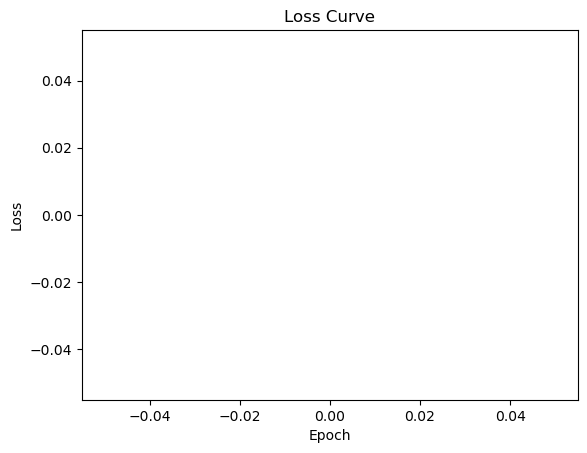

ComplexF64[-0.4085164005505317 + 0.5823942527784433im -0.4875821304808368 + 0.16037308762973285im 0.2796568146870743 + 0.014914454124164369im 0.1606283009691637 - 0.31393195478415686im; -0.33300385329096244 + 0.9633718155956109im 0.8713471638662657 - 0.3944002631846325im -0.11270761366112543 + 0.260094387435871im -0.7013013159486201 - 0.16502352368270165im; 0.056854939922080475 - 0.49728913923003404im 0.3558789186961475 - 0.15405429851402436im -0.07667165711437648 + 0.31542381632026795im -0.9332148971744397 + 0.5226454955446835im; 0.4514956414583613 + 0.5797103026935156im -0.8072153409078233 + 0.03473500557470854im -0.8636072770078985 + 0.08986353106799173im 0.31570173834619314 + 0.14892050187852787im]
Epoch: 1, Loss: 79.7893387747755 + 0.0im


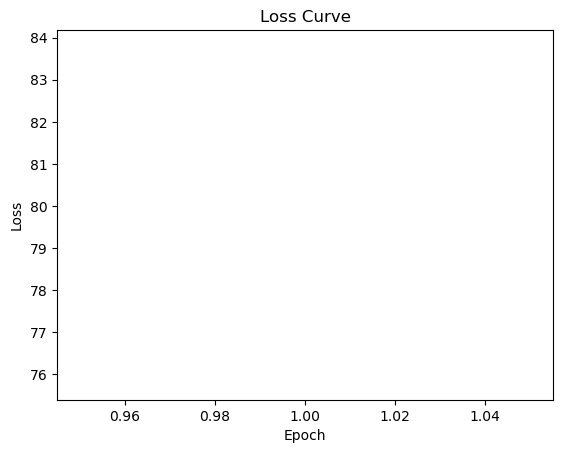

In [ ]:
train(opt,[layer],x,t,D,epochs=1)

In [ ]:
grad

9-element Vector{Spin_matrix}:
 [-0.4085052296431968 + 0.0im -0.487591478304239 + 0.0im 0.279638356914802 + 0.0im 0.16063381735875737 + 0.0im; -0.3329574838062399 + 0.0im 0.8713286092643102 + 0.0im -0.11268781463513733 + 0.0im -0.701317048878991 + 0.0im; 0.05680789172402001 + 0.0im 0.35583127555582905 + 0.0im -0.07672724677831866 + 0.0im -0.9332296713182586 + 0.0im; 0.45153569772082847 + 0.0im -0.8071765478234738 + 0.0im -0.8635794301881106 + 0.0im 0.3157225592076429 + 0.0im]
 [0.4751669280267379 + 0.0im -1.0702365216275211 + 0.0im -0.18793997469401802 + 0.0im 0.11391989573894534 + 0.0im; -0.16295160776280682 + 0.0im 0.2701085577427875 + 0.0im 0.08498375336785102 + 0.0im 1.1681564160426205 + 0.0im; -0.29362894338191836 + 0.0im -0.11811920330728753 + 0.0im 0.13289849221109762 + 0.0im -0.12746284028253285 + 0.0im; 0.7261917289724806 + 0.0im 0.361879415322619 + 0.0im 0.14228760392143158 + 0.0im -0.5762672117270995 + 0.0im]
 [0.11274607913946966 + 0.0im -0.05013305326428963 + 0.0im 0.06922